# 02 · EDA — seasonality, events, SNAP, price effects, intermittency

In [1]:
import sys; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from src.config import *
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})

df = pd.read_parquet(PROC_DIR / "long.parquet")
df["dow"] = df.date.dt.dayofweek; df["month"] = df.date.dt.month

## Day-of-week and monthly seasonality

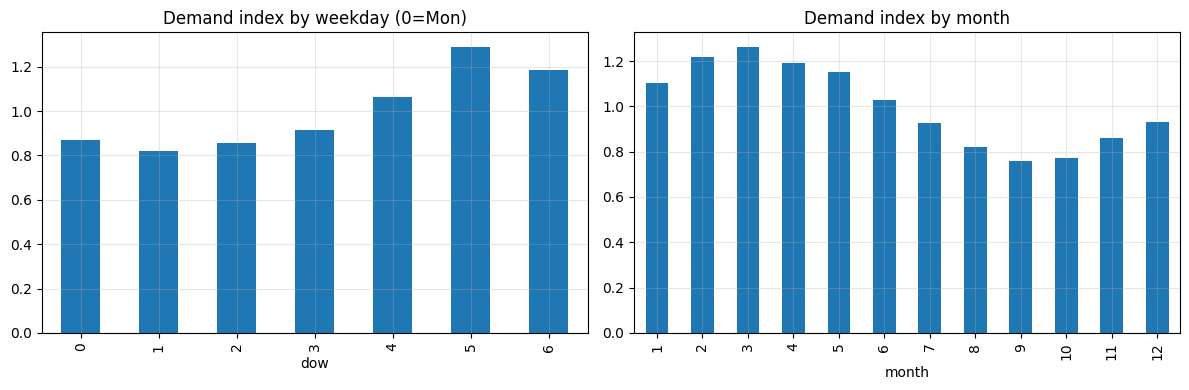

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(df.groupby("dow")["sales"].mean() / df["sales"].mean()).plot.bar(ax=ax[0], title="Demand index by weekday (0=Mon)")
(df.groupby("month")["sales"].mean() / df["sales"].mean()).plot.bar(ax=ax[1], title="Demand index by month")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_seasonality.png", dpi=120); plt.show()

## SNAP days and holidays/events

In [3]:
snap = df.groupby(["cat_id", "snap"])["sales"].mean().unstack()
snap["uplift_%"] = (snap[1] / snap[0] - 1) * 100
print("Average units per series-day on SNAP vs non-SNAP days"); display(snap.round(3))
ev = df.assign(is_event=df.event_name_1.notna()).groupby("is_event")["sales"].mean()
print(f"Event-day uplift: {(ev[True] / ev[False] - 1) * 100:.1f}%")

Average units per series-day on SNAP vs non-SNAP days


snap,0,1,uplift_%
cat_id,,,
FOODS,1.391,1.720,23.638
HOBBIES,1.400,1.477,5.480
HOUSEHOLD,1.232,1.287,4.528


Event-day uplift: 28.3%


## Price effects (promotions)
Prices are known in advance in M5, so they are legitimate features. We look at demand when the price is
below the item-store's own typical price.

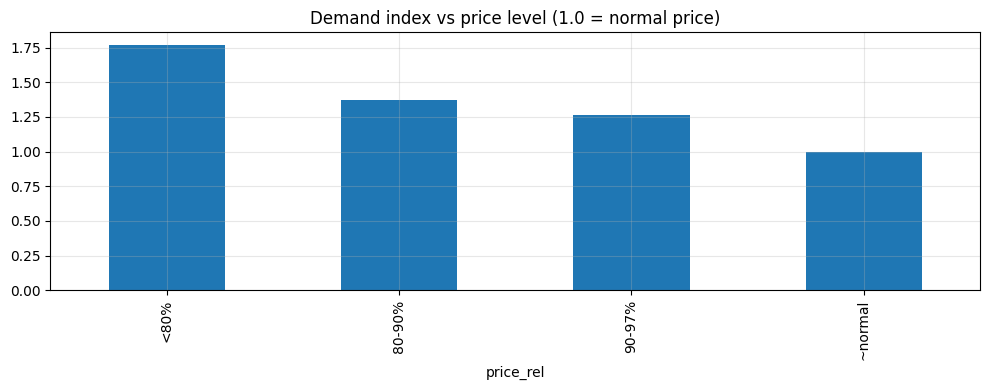

In [4]:
df["price_rel"] = df.sell_price / df.groupby("id")["sell_price"].transform("median")
bins = pd.cut(df.price_rel, [0, .8, .9, .97, 1.03, 10], labels=["<80%", "80-90%", "90-97%", "~normal", ">103%"])
rel = df.groupby(bins)["sales"].mean()
(rel / rel["~normal"]).plot.bar(title="Demand index vs price level (1.0 = normal price)")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_price_effect.png", dpi=120); plt.show()

## Intermittency — why RMSSE/WAPE and quantile models matter

Share of zero-sales days overall: 42.7%


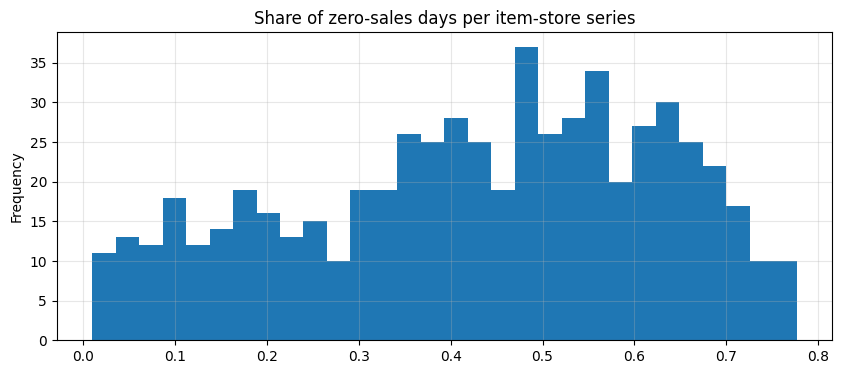

In [5]:
zero_share = df.groupby("id")["sales"].apply(lambda s: (s == 0).mean())
print(f"Share of zero-sales days overall: {(df.sales == 0).mean():.1%}")
zero_share.plot.hist(bins=30, title="Share of zero-sales days per item-store series")
plt.savefig(FIG_DIR / "02_intermittency.png", dpi=120); plt.show()

**Takeaways to put in the presentation:** weekly pattern strength, SNAP/event/price effects, and how
intermittent the data is — these justify the feature set in notebook 03 and the choice of a Tweedie
objective in notebook 05.